RNN (IMDB-3)

IMDb Genre Classification (Multi-Label)
Predict genres from plot description
SimpleRNN vs LSTM vs GRU

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import classification_report, f1_score, hamming_loss

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import pickle
import re
import string
from collections import Counter

In [2]:
df= pd.read_csv(r"L:\4th sem\Mission Scopus\ML Datasets\IMDB\IMBD.csv")

In [3]:
values= {"year":"(2016-2020)", "certificate":"TV-MV", "duration":"90 m"}
df.fillna(value=values, inplace=True)
df.head()

,title,year,certificate,duration,genre,rating,description,stars,votes
0,Cobra Kai,(2018– ),TV-14,30 min,"Action, Comedy, Drama",8.5,Decades after their 1984 All Valley Karate Tou...,"['Ralph Macchio, ', 'William Zabka, ', 'Courtn...","177,031"
1,The Crown,(2016– ),TV-MA,58 min,"Biography, Drama, History",8.7,Follows the political rivalries and romance of...,"['Claire Foy, ', 'Olivia Colman, ', 'Imelda St...","199,885"
2,Better Call Saul,(2015–2022),TV-MA,46 min,"Crime, Drama",8.9,The trials and tribulations of criminal lawyer...,"['Bob Odenkirk, ', 'Rhea Seehorn, ', 'Jonathan...","501,384"
3,Devil in Ohio,-2022,TV-MA,356 min,"Drama, Horror, Mystery",5.9,When a psychiatrist shelters a mysterious cult...,"['Emily Deschanel, ', 'Sam Jaeger, ', 'Gerardo...","9,773"
4,Cyberpunk: Edgerunners,(2022– ),TV-MA,24 min,"Animation, Action, Adventure",8.6,A Street Kid trying to survive in a technology...,"['Zach Aguilar, ', 'Kenichiro Ohashi, ', 'Emi ...","15,413"


In [4]:
df["rating"]= df["rating"].fillna(df["rating"].mean(), inplace=True)

C:\Users\DELL\AppData\Local\Temp\ipykernel_17192\1489462808.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["rating"]= df["rating"].fillna(df["rating"].mean(), inplace=True)


In [5]:
# Remove commas from the rating column
df["votes"] = df["votes"].str.replace(",", "", regex=False)

# Convert the column to numeric (float)
# errors='coerce' will turn any unparseable values into NaN
df["votes"] = pd.to_numeric(df["votes"], errors="coerce")

In [6]:
# Now this will work because the column is numbers
df["votes"] = df["votes"].fillna(df["votes"].mean())

In [7]:
df.dropna(inplace=True)

In [8]:
df.isnull().sum()

title          0
year           0
certificate    0
duration       0
genre          0
rating         0
description    0
stars          0
votes          0
dtype: int64

In [9]:
df.shape

(9884, 9)

Process Genres (Multi-label)

In [10]:
def extract_genres(genre_str):
    return [g.strip() for g in str(genre_str).split(",") if g.strip()]

df["genre_list"] = df["genre"].apply(extract_genres)

Count all individual genres

In [11]:
all_genres = [g for sublist in df["genre_list"] for g in sublist]
genre_counts = Counter(all_genres)

In [14]:
print("\nTop 50 genres:")
print(genre_counts.most_common(50))


Top 50 genres:
[('Drama', 4194), ('Comedy', 3098), ('Action', 1969), ('Adventure', 1563), ('Crime', 1491), ('Animation', 1434), ('Documentary', 1349), ('Romance', 1007), ('Thriller', 889), ('Mystery', 768), ('Fantasy', 555), ('Horror', 530), ('Family', 493), ('Reality-TV', 456), ('History', 415), ('Biography', 390), ('Short', 351), ('Sci-Fi', 293), ('Music', 236), ('Sport', 188), ('Game-Show', 86), ('Musical', 84), ('War', 73), ('Talk-Show', 55), ('Western', 34), ('News', 23), ('Film-Noir', 12)]


Keep only the most frequent genres (top 25 recommended)

In [15]:
TOP_N_GENRES = 25
top_genres = [g for g, c in genre_counts.most_common(TOP_N_GENRES)]
print(f"\nUsing top {TOP_N_GENRES} genres:", top_genres)


Using top 25 genres: ['Drama', 'Comedy', 'Action', 'Adventure', 'Crime', 'Animation', 'Documentary', 'Romance', 'Thriller', 'Mystery', 'Fantasy', 'Horror', 'Family', 'Reality-TV', 'History', 'Biography', 'Short', 'Sci-Fi', 'Music', 'Sport', 'Game-Show', 'Musical', 'War', 'Talk-Show', 'Western']


Filter genre_list to keep only top genres

In [16]:
df["genre_list"] = df["genre_list"].apply(lambda x: [g for g in x if g in top_genres])

Remove rows that have no genres left after filtering

In [17]:
df = df[df["genre_list"].map(len) > 0].copy()
print("Final samples:", len(df))

Final samples: 9879


Multi-hot encode the genres

In [18]:
mlb = MultiLabelBinarizer(classes=top_genres)
y = mlb.fit_transform(df["genre_list"])

print("Labels shape:", y.shape)          # (samples, num_genres)
print("Classes:", mlb.classes_)

Labels shape: (9879, 25)
Classes: ['Drama' 'Comedy' 'Action' 'Adventure' 'Crime' 'Animation' 'Documentary'
 'Romance' 'Thriller' 'Mystery' 'Fantasy' 'Horror' 'Family' 'Reality-TV'
 'History' 'Biography' 'Short' 'Sci-Fi' 'Music' 'Sport' 'Game-Show'
 'Musical' 'War' 'Talk-Show' 'Western']


Text Cleaning

In [19]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_description"] = df["description"].apply(clean_text)
texts = df["clean_description"].values

Tokenization & Padding

In [23]:
vocab_size = 10000
max_length = 150
embed_dim = 16
rnn_units = 32
num_classes = len(top_genres)

tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)
X_pad = pad_sequences(sequences, maxlen=max_length, padding="post", truncating="post")

print("\nPadded sequences shape:", X_pad.shape)


Padded sequences shape: (9879, 150)


Split

In [21]:
X_train, X_test, y_train, y_test = train_test_split(X_pad, y, test_size=0.2, random_state=42)

In [22]:
print("Train size:", len(X_train))
print("Test size :", len(X_test))

Train size: 7903
Test size : 1976


Model Creation and Training for SimpleRNN.

In [24]:
input_layer= Input(shape= (max_length,), name= "Input_Layer")
embedding_layer= Embedding(input_dim= vocab_size, output_dim= embed_dim, mask_zero= True, name= "Embedding_Layer")(input_layer)

In [25]:
rnn= SimpleRNN(units= rnn_units, return_sequences= False, return_state= False, name= "SimpleRNN_Layer")
embedding_layer_second= rnn(embedding_layer)
embedding_layer_third= Dropout(0.4)(embedding_layer_second)
embedding_layer_fourth= Dense(64, activation="relu")(embedding_layer_third)
embedding_layer_last= Dropout(0.3)(embedding_layer_fourth)
output_layer= Dense(units= num_classes, activation= "sigmoid", name= "Output_Layer")(embedding_layer_last)

c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


In [26]:
model= Model(inputs= input_layer, outputs= output_layer)

In [27]:
model.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])

In [28]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer (InputLayer)        │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding_Layer (Embedding)     │ (None, 150, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165,305 (645.72 KB)

 Trainable params: 165,305 (645.72 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
simple_rnn_model= model.fit(X_pad, y, epochs= 10, batch_size= 128, validation_split= 0.2, verbose= 1)

Epoch 1/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 12s 131ms/step - accuracy: 0.1272 - loss: 0.4400 - val_accuracy: 0.4904 - val_loss: 0.2747
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.2971 - loss: 0.2755 - val_accuracy: 0.4904 - val_loss: 0.2687
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.3463 - loss: 0.2637 - val_accuracy: 0.4904 - val_loss: 0.2679
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.3700 - loss: 0.2576 - val_accuracy: 0.4904 - val_loss: 0.2677
Epoch 5/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - accuracy: 0.3690 - loss: 0.2532 - val_accuracy: 0.4904 - val_loss: 0.2687
Epoch 6/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.3743 - loss: 0.2492 - val_accuracy: 0.4904 - val_loss: 0.2689
Epoch 7/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.3926 - loss: 0.2458 - val_accuracy: 0.4904 - val_loss: 0.2703
Epoch 8/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 70ms/step - accuracy: 0.4009 - loss: 0.2420 - val_accuracy: 0.4398 -

Model Creation and Training for LSTM.

In [31]:
input_layer2= Input(shape= (max_length,), name= "Input_Layer2")
embedding_layer2= Embedding(input_dim= vocab_size, output_dim= embed_dim, mask_zero= False, name= "Embedding_Layer2")(input_layer2)

In [32]:
rnn2= LSTM(units= rnn_units, return_sequences= False, return_state= False, name= "LSTM_Layer")
embedding_layer_second2= rnn(embedding_layer2)
embedding_layer_third2= Dropout(0.4)(embedding_layer_second2)
embedding_layer_fourth2= Dense(64, activation="relu")(embedding_layer_third2)
embedding_layer_last2= Dropout(0.3)(embedding_layer_fourth2)
output_layer2= Dense(units= num_classes, activation= "sigmoid", name= "Output_Layer")(embedding_layer_last2)

In [33]:
model2= Model(inputs= input_layer2, outputs= output_layer2)

In [34]:
model2.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])

In [35]:
model2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer2 (InputLayer)       │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding_Layer2 (Embedding)    │ (None, 150, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165,305 (645.72 KB)

 Trainable params: 165,305 (645.72 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
lstm_model= model2.fit(X_pad, y, epochs= 10, batch_size= 128, validation_split= 0.2, verbose= 1)

Epoch 1/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 10s 124ms/step - accuracy: 0.2038 - loss: 0.4353 - val_accuracy: 0.4904 - val_loss: 0.2809
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.2891 - loss: 0.2759 - val_accuracy: 0.4904 - val_loss: 0.2703
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 58ms/step - accuracy: 0.3251 - loss: 0.2663 - val_accuracy: 0.4904 - val_loss: 0.2687
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.3448 - loss: 0.2606 - val_accuracy: 0.4904 - val_loss: 0.2682
Epoch 5/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 63ms/step - accuracy: 0.3599 - loss: 0.2590 - val_accuracy: 0.4904 - val_loss: 0.2670
Epoch 6/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.3766 - loss: 0.2561 - val_accuracy: 0.4904 - val_loss: 0.2673
Epoch 7/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.3882 - loss: 0.2549 - val_accuracy: 0.4904 - val_loss: 0.2673
Epoch 8/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.3944 - loss: 0.2538 - val_accuracy: 0.4904 -

Model Creation and Training for GRU.

In [37]:
input_layer3= Input(shape= (max_length,), name= "Input_Layer3")
embedding_layer3= Embedding(input_dim= vocab_size, output_dim= embed_dim, mask_zero= False, name= "Embedding_Layer3")(input_layer3)

In [38]:
rnn3= GRU(units= rnn_units, return_sequences= False, return_state= False, name= "GRU_Layer")
embedding_layer_second3= rnn(embedding_layer3)
embedding_layer_third3= Dropout(0.4)(embedding_layer_second3)
embedding_layer_fourth3= Dense(64, activation="relu")(embedding_layer_third3)
embedding_layer_last3= Dropout(0.3)(embedding_layer_fourth3)
output_layer3= Dense(units= num_classes, activation= "sigmoid", name= "Output_Layer")(embedding_layer_last3)

In [39]:
model3= Model(inputs= input_layer3, outputs= output_layer3)

In [40]:
model3.compile(optimizer=Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])

In [41]:
model3.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Layer3 (InputLayer)       │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Embedding_Layer3 (Embedding)    │ (None, 150, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SimpleRNN_Layer (SimpleRNN)     │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165,305 (645.72 KB)

 Trainable params: 165,305 (645.72 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
gru_model= model3.fit(X_pad, y, epochs= 10, batch_size= 128, validation_split= 0.2, verbose= 1)

Epoch 1/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 9s 102ms/step - accuracy: 0.0935 - loss: 0.4605 - val_accuracy: 0.2606 - val_loss: 0.2848
Epoch 2/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 46ms/step - accuracy: 0.3076 - loss: 0.2737 - val_accuracy: 0.4904 - val_loss: 0.2690
Epoch 3/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.3392 - loss: 0.2640 - val_accuracy: 0.4904 - val_loss: 0.2679
Epoch 4/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.3597 - loss: 0.2599 - val_accuracy: 0.4904 - val_loss: 0.2676
Epoch 5/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.3776 - loss: 0.2572 - val_accuracy: 0.4904 - val_loss: 0.2673
Epoch 6/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.3804 - loss: 0.2554 - val_accuracy: 0.4904 - val_loss: 0.2670
Epoch 7/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.3858 - loss: 0.2550 - val_accuracy: 0.4904 - val_loss: 0.2667
Epoch 8/10
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.3929 - loss: 0.2535 - val_accuracy: 0.4904 - 

Binding 3 models

In [43]:
models = {
    "SimpleRNN": model,
    "LSTM": model2,
    "GRU": model3,
}

results = {}

In [44]:
history = {"SimpleRNN": model.history.history, "LSTM": model2.history.history, "GRU": model3.history.history}

Evaluate

In [45]:
for name, m in models.items():
    loss, acc = m.evaluate(X_test, y_test, verbose=0)
    results[name] = {"loss": loss, "accuracy": acc}
    print(f"\n{name} → Test Binary Accuracy: {acc:.4f} | Test Loss: {loss:.4f}")


SimpleRNN → Test Binary Accuracy: 0.3963 | Test Loss: 0.2537

LSTM → Test Binary Accuracy: 0.4150 | Test Loss: 0.2751

GRU → Test Binary Accuracy: 0.4150 | Test Loss: 0.2532


Detailed Evaluation

In [46]:
print("\n" + "="*60)
print("DETAILED EVALUATION")
print("="*60)

final_results = {}

for name, model in models.items():
    y_pred_prob = model.predict(X_test, verbose=0)
    y_pred = (y_pred_prob >= 0.5).astype(int)
    
    # Micro and Macro F1
    f1_micro = f1_score(y_test, y_pred, average="micro", zero_division=0)
    f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)
    ham_loss = hamming_loss(y_test, y_pred)
    
    final_results[name] = {
        "F1 Micro": f1_micro,
        "F1 Macro": f1_macro,
        "Hamming Loss": ham_loss
    }
    print(f"\n{name}:")
    print(f"  F1 Micro     : {f1_micro:.4f}")
    print(f"  F1 Macro     : {f1_macro:.4f}")
    print(f"  Hamming Loss : {ham_loss:.4f}")

results_df = pd.DataFrame(final_results).T.sort_values("F1 Micro", ascending=False)
print("\n" + "="*60)
print("FINAL COMPARISON (sorted by F1 Micro)")
print("="*60)
print(results_df)


DETAILED EVALUATION


c:\Users\DELL\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\layer.py:1062: UserWarning: Layer 'SimpleRNN_Layer' (of type SimpleRNN) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(



SimpleRNN:
  F1 Micro     : 0.0080
  F1 Macro     : 0.0029
  Hamming Loss : 0.0904

LSTM:
  F1 Micro     : 0.0000
  F1 Macro     : 0.0000
  Hamming Loss : 0.0903

GRU:
  F1 Micro     : 0.0000
  F1 Macro     : 0.0000
  Hamming Loss : 0.0903

FINAL COMPARISON (sorted by F1 Micro)
           F1 Micro  F1 Macro  Hamming Loss
SimpleRNN  0.007998  0.002919      0.090385
LSTM       0.000000  0.000000      0.090263
GRU        0.000000  0.000000      0.090263


Classification report of best model

In [47]:
best_model_name = results_df.index[0]
best_model = models[best_model_name]
y_pred_best = (best_model.predict(X_test, verbose=0) >= 0.5).astype(int)

print(f"\nClassification Report ({best_model_name}):")
print(classification_report(y_test, y_pred_best, target_names=mlb.classes_, zero_division=0))


Classification Report (SimpleRNN):
              precision    recall  f1-score   support

       Drama       0.71      0.01      0.01       820
      Comedy       0.00      0.00      0.00       643
      Action       0.38      0.03      0.06       393
   Adventure       0.00      0.00      0.00       331
       Crime       0.00      0.00      0.00       314
   Animation       0.00      0.00      0.00       294
 Documentary       0.00      0.00      0.00       271
     Romance       0.00      0.00      0.00       179
    Thriller       0.00      0.00      0.00       161
     Mystery       0.00      0.00      0.00       152
     Fantasy       0.00      0.00      0.00       117
      Horror       0.00      0.00      0.00       101
      Family       0.00      0.00      0.00       122
  Reality-TV       0.00      0.00      0.00       102
     History       0.00      0.00      0.00        74
   Biography       0.00      0.00      0.00        92
       Short       0.00      0.00      0.00  

Training Curves

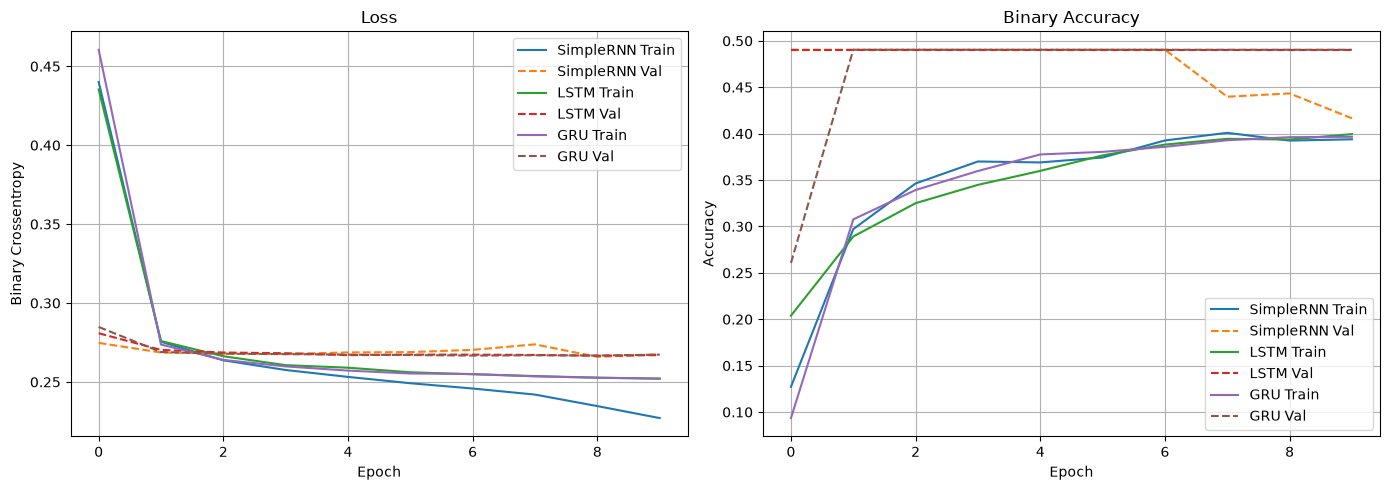

In [49]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
for name, hist in history.items():
    plt.plot(hist["loss"], label=f"{name} Train")
    plt.plot(hist["val_loss"], label=f"{name} Val", linestyle="--")
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
for name, hist in history.items():
    plt.plot(hist["accuracy"], label=f"{name} Train")
    plt.plot(hist["val_accuracy"], label=f"{name} Val", linestyle="--")
plt.title("Binary Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Save Best Model + Tokenizer + other objects

In [50]:
best_model.save(f"imdb_genre_{best_model_name.lower()}.h5")
print(f"\nBest model saved as: imdb_genre_{best_model_name.lower()}.h5")

with open("tokenizer_imdb_genre.pickle", "wb") as f:
    pickle.dump(tokenizer, f)

with open("max_length_imdb_genre.pickle", "wb") as f:
    pickle.dump(max_length, f)

with open("mlb_imdb_genre.pickle", "wb") as f:
    pickle.dump(mlb, f)

print("Tokenizer, max_length and MultiLabelBinarizer saved.")


Best model saved as: imdb_genre_simplernn.h5
Tokenizer, max_length and MultiLabelBinarizer saved.


Now, I will create UI from these files.